# Membrane shapes

This notebook shows how `specter.specimen.membrane` builds lipid membranes, first through
the four ready-made organelle kinds and then by composing shapes from primitives.

A membrane is modelled as **the boundary of a solid**. The solid (a vesicle's lumen, a
tubule's interior, a cell under its plasma membrane) is described by a signed distance
$\phi(\mathbf{x})$ in Å, negative inside the solid and positive outside, so the membrane's
midplane is the surface $\phi = 0$. Three steps turn a solid into a potential volume:

1. **Geometry on a coarse grid.** $\phi$ is stored on a working grid of spacing
   $h = 10$ Å, independent of the output voxel size. A bilayer is smooth on that scale, so
   the geometry costs the same whatever resolution is rendered.
2. **Regularisation.** A ball of radius $r_\mathrm{min}$ (30 Å by default) is rolled over
   both sides of the surface, which removes every crease, neck and web tighter than that
   radius. The result is checked by its **reach**: the distance one can walk along the
   surface normal, on either side, before $\phi$ stops being an exact distance. A bilayer
   of thickness $t$ has its two leaflets at $\pm t/2$, so a reach above $t/2$ guarantees
   the leaflets neither fold over themselves nor touch another part of the membrane.
3. **Rendering.** Each output voxel within a few nm of the surface reads its signed
   distance $z$ from the coarse field and looks up the calibrated bilayer profile
   $\psi(z)$, the plane-averaged electrostatic potential of a POPC bilayer in volts
   (headgroup peaks around an acyl core).

The notebook runs in about a minute on a GPU. It also runs on a CPU, but much more
slowly (well over ten minutes on a busy 128-core host); to shorten a CPU run, drop
`"mitochondrion"` from `kinds` in section 1, which alone takes two to three minutes
there.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from specter.specimen.membrane import (
    ORGANELLE_DEFAULTS,
    Grid,
    MembraneGenerator,
    ReachError,
    reach,
    regularise,
    render_bilayer,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


Two small helpers are used throughout. `timed` measures a call's wall time (waiting for
the GPU to finish first, since CUDA calls return before their work is done), and `show`
draws a volume's central slice beside its projection. Volumes are indexed `(Z, Y, X)`;
the `axis` argument selects which axis is cut and summed (0 for z, 1 for y).

In [2]:
def timed(function, *args, **kwargs):
    """Call `function` and return (result, seconds)."""
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    result = function(*args, **kwargs)
    if device == "cuda":
        torch.cuda.synchronize()
    return result, time.perf_counter() - start


def show(volume, voxel_size, title, axes, axis=0):
    """Central slice (left) and projection (right) of a (Z, Y, X) volume."""
    volume = volume.detach().float().cpu()
    panels = (
        volume.select(axis, volume.shape[axis] // 2),
        volume.sum(axis) * voxel_size,
    )
    for ax, image, what in zip(axes, panels, ("central slice", "projection")):
        ax.imshow(image.numpy(), cmap="gray_r", origin="lower")
        ax.set_title(f"{title}\n{what}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

## 1. The four organelle kinds

`MembraneGenerator` builds one organelle. Its `kind` is one of `"vesicle"`, `"tubules"`,
`"cisterna"` or `"mitochondrion"`, and each kind has a small set of settings that describe
it in cell-biological terms. `ORGANELLE_DEFAULTS` lists them with their default values.
Every length is in Å.

| kind | setting | meaning |
|---|---|---|
| `vesicle` | `radius` | radius of the sphere of equal volume |
| | `elongation` | long axis over short axis (1 is a sphere) |
| | `undulation` | standard deviation of the random surface relief |
| | `layers` | number of nested bilayers (1 is a plain vesicle) |
| `tubules` | `radius` | tube radius |
| | `length` | length of each branch |
| | `branches` | number of branches meeting at one junction |
| `cisterna` | `diameter` | width of the flattened sac |
| | `lumen_width` | thickness of the sac, membrane midplane to midplane |
| | `fenestrations` | number of holes through the sac |
| `mitochondrion` | `radius` | radius of the capsule |
| | `length` | length of the capsule's straight part |
| | `crista_spacing` | distance between neighbouring cristae |
| | `membrane_gap` | distance from the outer to the inner membrane |

In [3]:
for kind, settings in ORGANELLE_DEFAULTS.items():
    print(kind)
    for name, value in settings.items():
        print(f"    {name:<15} {value}")

vesicle
    radius          [200.0, 340.0]
    elongation      [1.0, 1.5]
    undulation      [5.0, 45.0]
    layers          1
tubules
    radius          [110.0, 170.0]
    length          [1200.0, 1800.0]
    branches        [2, 4]
cisterna
    diameter        [800.0, 1120.0]
    lumen_width     [100.0, 160.0]
    fenestrations   [0, 1]
mitochondrion
    radius          [470.0, 560.0]
    length          [900.0, 1440.0]
    crista_spacing  [230.0, 330.0]
    membrane_gap    130.0


### One of each

The generator takes the output `voxel_size` (Å per voxel), a `device` and a `seed`. With
no `target_shape` the output box is sized to hold the organelle. Sizes are drawn when the
generator is constructed, so `gen.params` (the values this instance drew) and
`gen.bounding_radius` (the radius, in Å, of a sphere that contains it) are available
before any geometry is built. `gen.generate()` then returns the potential volume in volts,
indexed `(Z, Y, X)`.

The mitochondrion is the most expensive kind because it holds three surfaces (outer
membrane, inner boundary membrane, cristae) in the largest box: about 5 s on a GPU and
two to three minutes on a CPU, where the other kinds take 5 to 25 s each.

vesicle: 0.5 s, volume (74, 74, 74), peak 5.8 V
    params {'radius': 247.0, 'elongation': 1.4, 'undulation': 19.0, 'layers': 1.0}
    bounding radius 420 Å


tubules: 1.0 s, volume (96, 152, 152), peak 5.8 V
    params {'radius': 130.1, 'length': 1693.7, 'branches': 2.0}
    bounding radius 1347 Å


cisterna: 1.1 s, volume (64, 124, 124), peak 5.8 V
    params {'diameter': 907.3, 'lumen_width': 149.4, 'fenestrations': 0.0}
    bounding radius 802 Å


mitochondrion: 5.6 s, volume (126, 238, 132), peak 5.8 V
    params {'radius': 500.2, 'length': 1344.3, 'crista_spacing': 265.0, 'membrane_gap': 130.0}
    bounding radius 1412 Å


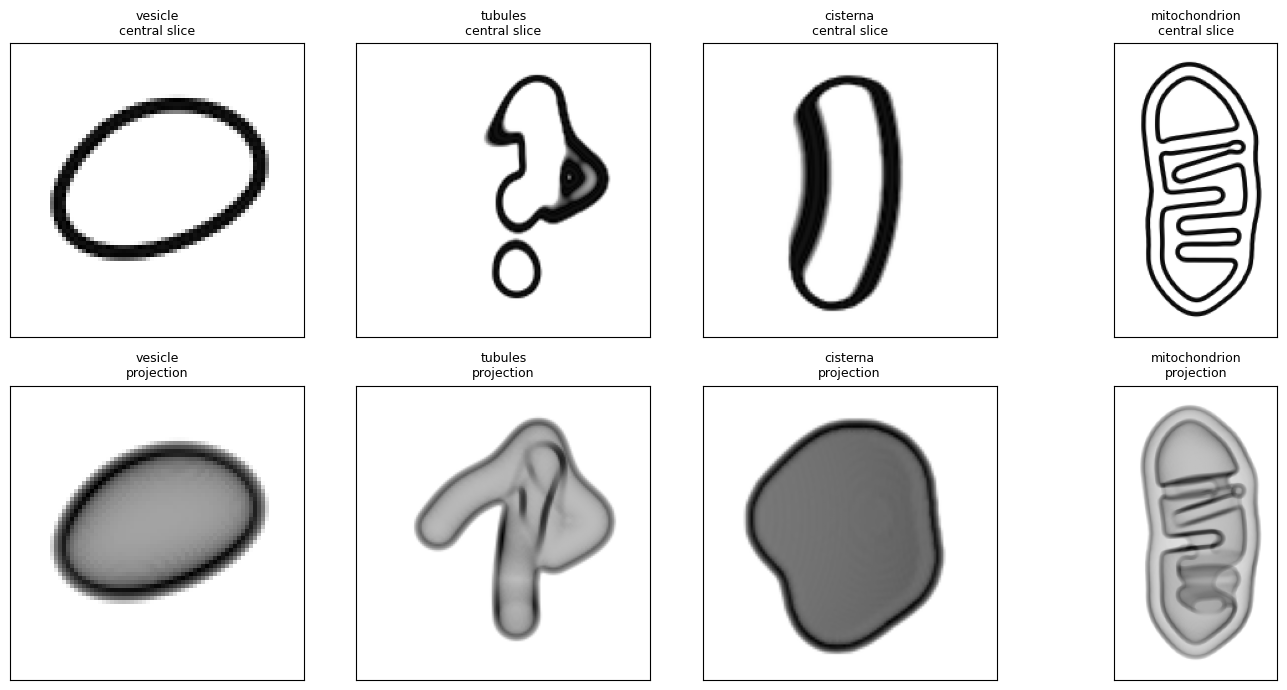

In [4]:
voxel_size = 12.0  # Å per voxel of the rendered volume
kinds = ("vesicle", "tubules", "cisterna", "mitochondrion")

# The first call also builds the bilayer profile, so warm that up outside the timings.
MembraneGenerator(
    kind="vesicle", voxel_size=voxel_size, device=device, seed=0
).generate()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for column, kind in enumerate(kinds):
    gen = MembraneGenerator(kind=kind, voxel_size=voxel_size, device=device, seed=3)
    volume, seconds = timed(gen.generate)
    params = {name: round(value, 1) for name, value in gen.params.items()}
    print(
        f"{kind}: {seconds:.1f} s, volume {tuple(volume.shape)}, peak {volume.max():.1f} V"
    )
    print(f"    params {params}")
    print(f"    bounding radius {gen.bounding_radius:.0f} Å")
    show(volume, voxel_size, kind, axes[:, column])
fig.tight_layout()

### A scalar fixes a setting, a range draws it

Each setting accepts either a scalar, which every instance shares, or a `[low, high]`
pair, from which each instance draws uniformly using its `seed`. A setting that is left
out takes the kind's default range. The cell below constructs generators without
generating them, which is enough to read what each seed drew.

In [5]:
print("radius = 250.0 (scalar), elongation left at its default range")
for seed in range(4):
    gen = MembraneGenerator(kind="vesicle", radius=250.0, device=device, seed=seed)
    print(
        f"    seed {seed}: radius {gen.params['radius']:.1f}, elongation {gen.params['elongation']:.2f}"
    )

print("radius = [150.0, 350.0] (range)")
for seed in range(4):
    gen = MembraneGenerator(
        kind="vesicle", radius=[150.0, 350.0], device=device, seed=seed
    )
    print(
        f"    seed {seed}: radius {gen.params['radius']:.1f}, elongation {gen.params['elongation']:.2f}"
    )

radius = 250.0 (scalar), elongation left at its default range
    seed 0: radius 250.0, elongation 1.23
    seed 1: radius 250.0, elongation 1.19
    seed 2: radius 250.0, elongation 1.40
    seed 3: radius 250.0, elongation 1.41
radius = [150.0, 350.0] (range)
    seed 0: radius 211.2, elongation 1.23
    seed 1: radius 153.6, elongation 1.19
    seed 2: radius 209.5, elongation 1.40
    seed 3: radius 217.1, elongation 1.41


A setting that does not belong to the kind, or a value below what the kind can build, is
refused when the generator is constructed.

In [6]:
for settings in (
    {"kind": "vesicle", "length": 500.0},
    {"kind": "tubules", "radius": 20.0},
):
    try:
        MembraneGenerator(device=device, seed=0, **settings)
    except ValueError as error:
        print(f"{settings}\n    ValueError: {error}\n")

{'kind': 'vesicle', 'length': 500.0}
    ValueError: membrane kind 'vesicle' has no setting 'length'; its settings are ['elongation', 'layers', 'radius', 'undulation']

{'kind': 'tubules', 'radius': 20.0}
    ValueError: tubules membrane radius = 20 is below the smallest supported value, 60



### Seeds

The seed controls everything random about an instance: the drawn sizes, the path each
tubule takes, the surface relief. The same seed reproduces the same organelle. Four seeds
of the `tubules` kind, shown in projection:

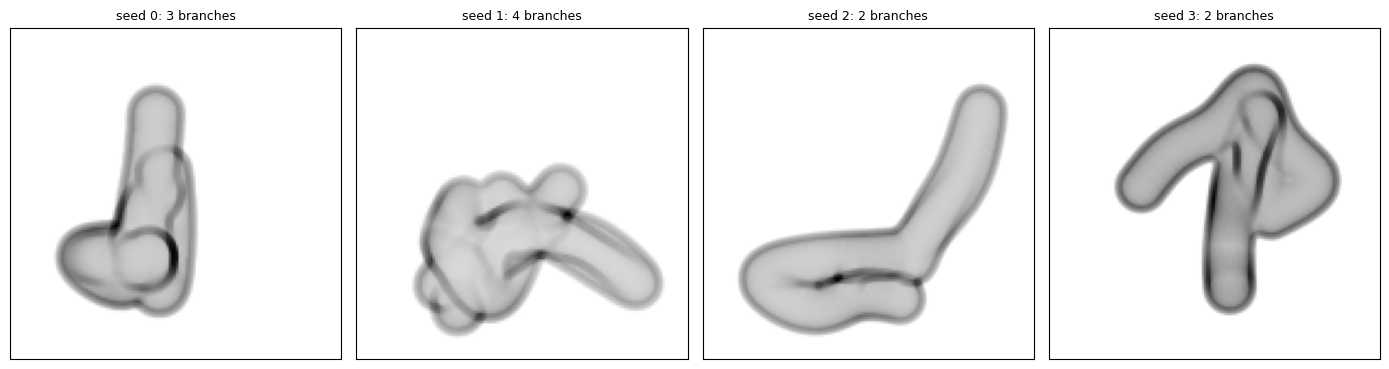

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, seed in zip(axes, range(4)):
    gen = MembraneGenerator(
        kind="tubules", voxel_size=voxel_size, device=device, seed=seed
    )
    volume = gen.generate()
    ax.imshow((volume.sum(0) * voxel_size).cpu().numpy(), cmap="gray_r", origin="lower")
    ax.set_title(f"seed {seed}: {gen.params['branches']:.0f} branches", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()

### Steering a kind with its settings

The settings span more than the default ranges show. Below: a three-layer (multilamellar)
vesicle, a strongly elongated vesicle, a single unbranched tubule and a cisterna with
three fenestrations.

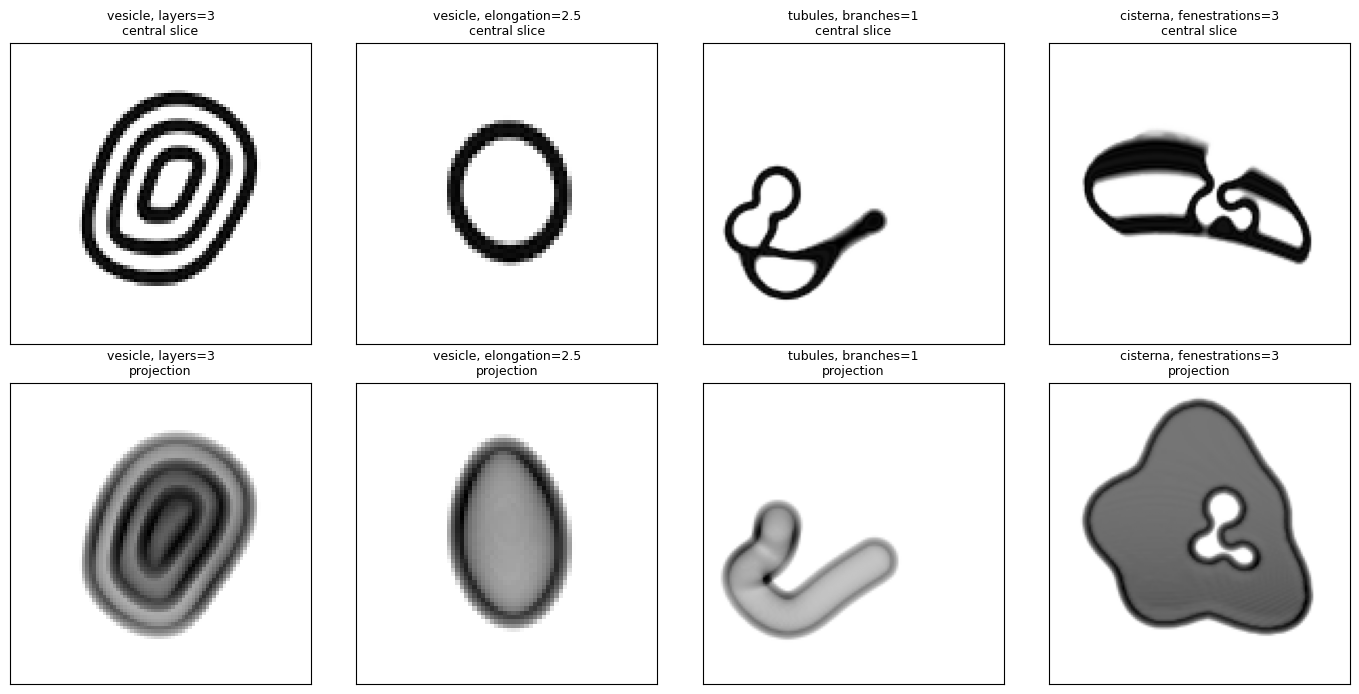

In [8]:
variants = {
    "vesicle, layers=3": dict(kind="vesicle", radius=300.0, layers=3),
    "vesicle, elongation=2.5": dict(
        kind="vesicle", radius=200.0, elongation=2.5, undulation=10.0
    ),
    "tubules, branches=1": dict(kind="tubules", branches=1, length=1500.0),
    "cisterna, fenestrations=3": dict(
        kind="cisterna", diameter=1100.0, fenestrations=3
    ),
}
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for column, (title, settings) in enumerate(variants.items()):
    gen = MembraneGenerator(voxel_size=voxel_size, device=device, seed=1, **settings)
    show(gen.generate(), voxel_size, title, axes[:, column])
fig.tight_layout()

### The same thing in a tomogram config

`specter build tomogram` reads the same kinds and settings from `[[membrane]]` tables, one
table per organelle population. `n_copies` is the number of instances; each instance draws
its own values from the ranges. The tables below ask for three vesicles, one branched
tubule and one mitochondrion (see `configs/tomogram.toml` for the full file):

```toml
[[membrane]]
kind = "vesicle"
radius = [150.0, 350.0]     # Å, drawn per instance
layers = 1
n_copies = 3

[[membrane]]
kind = "tubules"
radius = [110.0, 170.0]
length = [1200.0, 1800.0]
branches = 3                # a scalar: every instance has three branches
n_copies = 1

[[membrane]]
kind = "mitochondrion"
radius = [400.0, 500.0]
length = [900.0, 1400.0]
n_copies = 1
```

Sizes should be chosen against the thinnest axis of the tomogram: an organelle wider than
the slab is cut open by its faces, and an instance whose bounding sphere does not fit is
dropped with a warning.

## 2. Composing shapes from primitives

The organelle kinds are recipes over a small set of primitives, and the same primitives
are available for shapes the kinds do not cover. A shape is built in four steps:

1. make a `Grid`, the coarse working grid;
2. write the solid as a signed field $\phi$ by combining primitives;
3. `regularise` it, which also verifies the reach;
4. render one or more regularised fields with `render_bilayer`.

The primitives and the bilayer profile are exported from `specter.specimen.membrane`.

In [9]:
import specter.specimen.membrane as prim
from specter.specimen.membrane import build_measured_bilayer_profile

### The grid and the profile

`Grid(box_xyz, h=10.0)` covers a box of the given size in Å, ordered `(x, y, z)`, with
nodes every `h` Å, plus a margin on every side so that the rolling ball has room at the
box faces. Fields on it are tensors of shape `grid.shape`, also indexed `(x, y, z)`.

`build_measured_bilayer_profile` returns $\psi(z)$ for a bilayer of the given thickness
(phosphate to phosphate, 37 Å for fluid POPC).

In [10]:
grid = Grid((1000.0, 1000.0, 1000.0), device=device)
print("box (Å):", grid.box, "| node spacing h (Å):", grid.h)
print("field shape (x, y, z):", grid.shape, "| nodes:", grid.n_nodes)
print("rolling-ball radius r_min (Å):", grid.r_min)

bilayer_thickness = 37.0
profile = build_measured_bilayer_profile(
    thickness_angstrom=bilayer_thickness, device=device
)

box (Å): (1000.0, 1000.0, 1000.0) | node spacing h (Å): 10.0
field shape (x, y, z): (121, 121, 121) | nodes: 1771561
rolling-ball radius r_min (Å): 30.0


`render_bilayer(surfaces, grid, profile, shape_zyx, voxel_size, origin_xyz=...)` renders a
list of regularised fields into one volume. `shape_zyx` is the output shape in voxels and
`origin_xyz` the physical position of output voxel `(0, 0, 0)`. The helper below renders
exactly the grid's box.

In [11]:
def render(surfaces, grid, voxel_size=10.0):
    """Render regularised fields over the grid's box; returns a (Z, Y, X) volume in volts."""
    shape_zyx = tuple(int(round(extent / voxel_size)) for extent in grid.box[::-1])
    return render_bilayer(
        surfaces, grid, profile, shape_zyx, voxel_size, origin_xyz=tuple(grid.lo)
    )

### Primitives and how they combine

| function | solid |
|---|---|
| `ball(grid, centre, radius)` | sphere |
| `ellipsoid(grid, centre, radii, rot)` | ellipsoid with semi-axes `radii`, rotated by `rot` |
| `tube(grid, ctrl, radius)` | tube around a smooth curve through the control points `ctrl`; `radius` may be a function of the arc fraction 0 to 1 |
| `sheet(grid, centre, rot, outline, half, height, holes)` | slab of half-thickness `half` around a patch with edge `outline(theta)`, optionally bent by `height(u, v)` and pierced by `holes` |
| `cap(grid, centre, rot, radius, polar_max, half)` | cup: a slab around a spherical cap |
| `half_space(grid, z0, height)` | everything below the surface `z0 + height(x, y)` |
| `union(a, b, ...)` | the solids joined |
| `subtract(a, b)` | `a` with `b` carved out |
| `undulate(phi, grid, rng, amplitude, wavelength)` | surface displaced by smooth random relief |
| `nested(phi, grid, gap)` | the solid whose surface lies `gap` Å inside `phi` (already regularised) |

Helpers: `circle(r)` and `wobbly(r, rng)` are outlines for `sheet`; `rot_to(axis)` is the
rotation taking $+z$ to `axis`; `random_walk(rng, start, step, n)` gives control points
for a meandering tube; `curve(ctrl)` is the smooth curve through control points.

A union of two balls and a thin tube joining them has creases where the pieces meet, and
the tube (radius 20 Å) is thinner than a bilayer can enclose. `regularise` rolls the
creases into fillets and removes what is too thin: the tube disappears, leaving two
separate solids, while the small bleb keeps a smooth neck. The figure draws the
$\phi = 0$ contour on the central z-plane before and after.

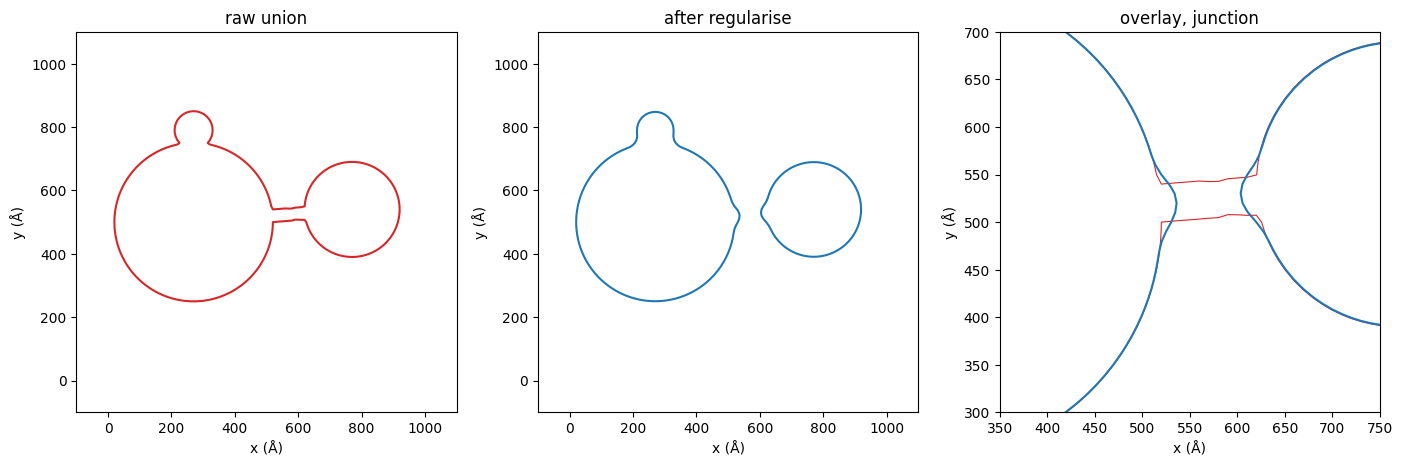

In [12]:
centre = grid.centre
a = centre + [-230.0, 0.0, 0.0]
b = centre + [270.0, 40.0, 0.0]
raw = prim.union(
    prim.ball(grid, a, 250.0),
    prim.ball(grid, b, 150.0),
    prim.tube(grid, [a, (a + b) / 2, b], 20.0),
    prim.ball(
        grid, centre + [-230.0, 290.0, 0.0], 60.0
    ),  # a small bleb, tangent to the big ball
)
smooth = regularise(raw, grid)

x, y, z = (axis.flatten().cpu().numpy() for axis in grid.axes())
k = int(np.argmin(np.abs(z - centre[2])))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (phi, color, label) in zip(
    axes, ((raw, "tab:red", "raw union"), (smooth, "tab:blue", "after regularise"))
):
    ax.contour(x, y, phi[:, :, k].cpu().numpy().T, levels=[0.0], colors=color)
    ax.set_title(label)
axes[2].contour(
    x, y, raw[:, :, k].cpu().numpy().T, levels=[0.0], colors="tab:red", linewidths=0.8
)
axes[2].contour(x, y, smooth[:, :, k].cpu().numpy().T, levels=[0.0], colors="tab:blue")
axes[2].set_title("overlay, junction")
axes[2].set_xlim(centre[0] - 150, centre[0] + 250)
axes[2].set_ylim(centre[1] - 200, centre[1] + 200)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("x (Å)")
    ax.set_ylabel("y (Å)")
fig.tight_layout()

### Reach

`reach(phi, grid)` returns the surface points, their unit normals, and the reach on the
outer and inner side of each point in Å (measured up to 80 Å). The minimum over the
surface is the number that matters: it must exceed half the bilayer thickness for the
leaflets to be well defined. `regularise` enforces 25 Å by default (`min_reach`).

raw union          18486 surface points | min reach outside   2.5 Å, inside   5.0 Å (needed: > 18.5 Å)
after regularise   18016 surface points | min reach outside  35.0 Å, inside  32.5 Å (needed: > 18.5 Å)


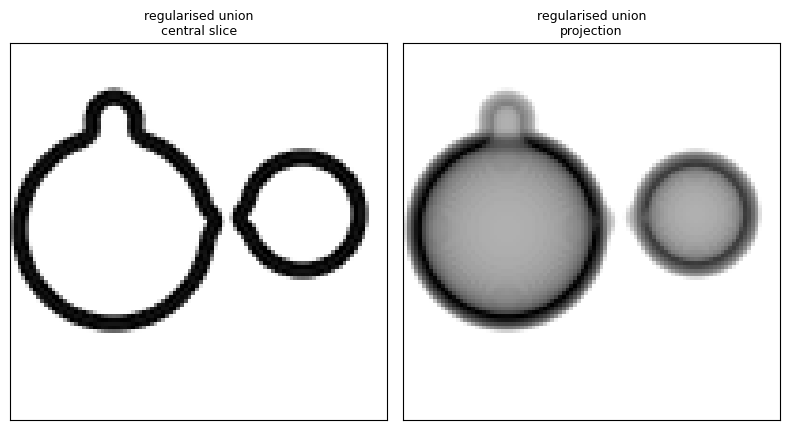

In [13]:
for label, phi in (("raw union", raw), ("after regularise", smooth)):
    points, normals, outer, inner = reach(phi, grid)
    print(
        f"{label:<17} {len(points):>6} surface points | "
        f"min reach outside {outer.min():5.1f} Å, inside {inner.min():5.1f} Å "
        f"(needed: > {bilayer_thickness / 2:.1f} Å)"
    )

volume = render([smooth], grid)
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2))
show(volume, 10.0, "regularised union", axes)
fig.tight_layout()

### A gallery of composed shapes

Eight recipes follow, each a few lines of primitives. A recipe returns its grid and a
list of regularised fields; a list with several entries renders several membranes into
one volume (the nested bilayers of a multilamellar vesicle, the sacs of a stack).

- **discocyte**: a disc whose half-thickness grows towards the rim, so both faces are
  concave (a red-cell shape).
- **stomatocyte**: a thick spherical cap, a vesicle folded into a cup.
- **budding vesicle**: two balls joined by a narrow neck.
- **pearled tubule**: a tube whose radius oscillates along its length.
- **tubule network**: tubes joining three junctions in a ring, with arms leaving the box.
- **cisterna stack**: five bent sacs, each regularised on its own.
- **multilamellar vesicle**: an undulated ball and three nested copies 78 Å apart.
- **plasma membrane**: a wavy half-space with an invagination, a shallow pit and a bud on
  a stalk.

In [14]:
def discocyte(rng):
    g = Grid((1000.0, 1000.0, 1000.0), device=device)
    phi = prim.sheet(
        g,
        g.centre,
        prim.rot_to([0.3, -0.2, 1.0]),
        prim.circle(330.0),
        lambda f: 42.0
        + 70.0 * np.clip(f, 0, 1) ** 3,  # half-thickness vs. radial fraction
    )
    return g, [regularise(phi, g)]


def stomatocyte(rng):
    g = Grid((1000.0, 1000.0, 1000.0), device=device)
    phi = prim.cap(
        g,
        g.centre + [0.0, 0.0, -30.0],
        prim.rot_to([0.25, 0.1, -1.0]),
        radius=270.0,
        polar_max=np.radians(118.0),
        half=85.0,
    )
    return g, [regularise(phi, g)]


def budding_vesicle(rng):
    g = Grid((1300.0, 1000.0, 1000.0), device=device)
    a = g.centre + [-200.0, 0.0, 0.0]
    b = g.centre + [330.0, 40.0, 30.0]
    phi = prim.union(
        prim.ball(g, a, 300.0),
        prim.ball(g, b, 170.0),
        prim.tube(g, [a, (a + b) / 2, b], 62.0),
    )
    return g, [regularise(phi, g)]


def pearled_tubule(rng):
    g = Grid((1600.0, 800.0, 800.0), device=device)
    ctrl = [
        g.centre + [x, 60.0 * np.sin(x / 300.0), 0.0] for x in np.linspace(-950, 950, 9)
    ]
    phi = prim.tube(g, ctrl, lambda s: 110.0 + 50.0 * np.sin(2 * np.pi * 5.5 * s))
    return g, [regularise(phi, g)]


def tubule_network(rng):
    g = Grid((1800.0, 1800.0, 1000.0), device=device)
    nodes = np.array([[500, 600, 500], [1200, 500, 420], [950, 1250, 600]], float)
    ends = np.array(
        [
            [-200, 300, 450],
            [2000, 150, 300],
            [1000, 2000, 700],
            [-200, 1300, 600],
            [2000, 1300, 500],
        ],
        float,
    )
    pairs = [(nodes[0], nodes[1]), (nodes[1], nodes[2]), (nodes[2], nodes[0])]
    pairs += [(nodes[0], ends[0]), (nodes[1], ends[1]), (nodes[2], ends[2])]
    pairs += [(nodes[2], ends[3]), (nodes[1], ends[4])]
    tubes = []
    for start, end in pairs:
        middle = (start + end) / 2 + rng.normal(size=3) * 70.0
        tubes.append(prim.tube(g, [start, middle, end], 130.0))
    return g, [regularise(prim.union(*tubes), g)]


def cisterna_stack(rng):
    g = Grid((1500.0, 1500.0, 1100.0), device=device)
    sacs = []
    for k in range(5):

        def bend(u, v, k=k):
            return u**2 / (2 * (1500.0 + 260.0 * k)) + 25.0 * np.sin(v / 300.0 + k)

        phi = prim.sheet(
            g,
            g.centre + [0.0, 0.0, -430.0 + 190.0 * k],
            np.eye(3),
            prim.wobbly(560.0 - 45.0 * k, rng, amp=0.1),
            52.0,
            bend,
        )
        sacs.append(regularise(phi, g))
    return g, sacs


def multilamellar_vesicle(rng):
    g = Grid((1000.0, 1000.0, 1000.0), device=device)
    outer = regularise(
        prim.undulate(prim.ball(g, g.centre, 350.0), g, rng, 25.0, 500.0), g
    )
    return g, [outer] + [prim.nested(outer, g, 78.0 * k) for k in range(1, 4)]


def plasma_membrane(rng):
    g = Grid((1800.0, 1800.0, 1100.0), pad=200.0, device=device)

    def wave(x, y):  # torch tensors: the grid's x and y axes
        return 45.0 * torch.sin(x / 330.0) * torch.cos(y / 410.0 + 1.0) + 0.04 * (
            x - 900.0
        )

    cell = prim.half_space(g, 520.0, wave)
    pit, bud = np.array([520.0, 900.0, 250.0]), np.array([1250.0, 900.0, 880.0])
    invagination = prim.union(
        prim.ball(g, pit, 190.0),
        prim.tube(g, [pit, pit + [0, 0, 180.0], pit + [0, 0, 420.0]], 75.0),
    )
    cell = prim.subtract(cell, invagination)
    cell = prim.union(
        cell,
        prim.ball(g, bud, 170.0),
        prim.tube(g, [bud, bud - [0, 0, 200.0], bud - [0, 0, 480.0]], 75.0),
    )
    cell = prim.subtract(cell, prim.ball(g, np.array([1300.0, 450.0, 560.0]), 210.0))
    return g, [regularise(cell, g)]

Each recipe is drawn as its central slice (top) and its projection (bottom). The first
seven are cut and projected along z; the plasma membrane is cut along y, so that the cell
is below the membrane and the invagination and the bud are seen side on.

discocyte              1 surface(s), geometry  0.4 s, min reach 37.5 Å


stomatocyte            1 surface(s), geometry  0.4 s, min reach 70.0 Å


budding_vesicle        1 surface(s), geometry  0.4 s, min reach 32.5 Å


pearled_tubule         1 surface(s), geometry  0.4 s, min reach 32.5 Å


tubule_network         1 surface(s), geometry  1.1 s, min reach 32.5 Å


cisterna_stack         5 surface(s), geometry  5.0 s, min reach 42.5 Å


multilamellar_vesicle  4 surface(s), geometry  1.6 s, min reach 35.0 Å


plasma_membrane        1 surface(s), geometry  0.6 s, min reach 27.5 Å


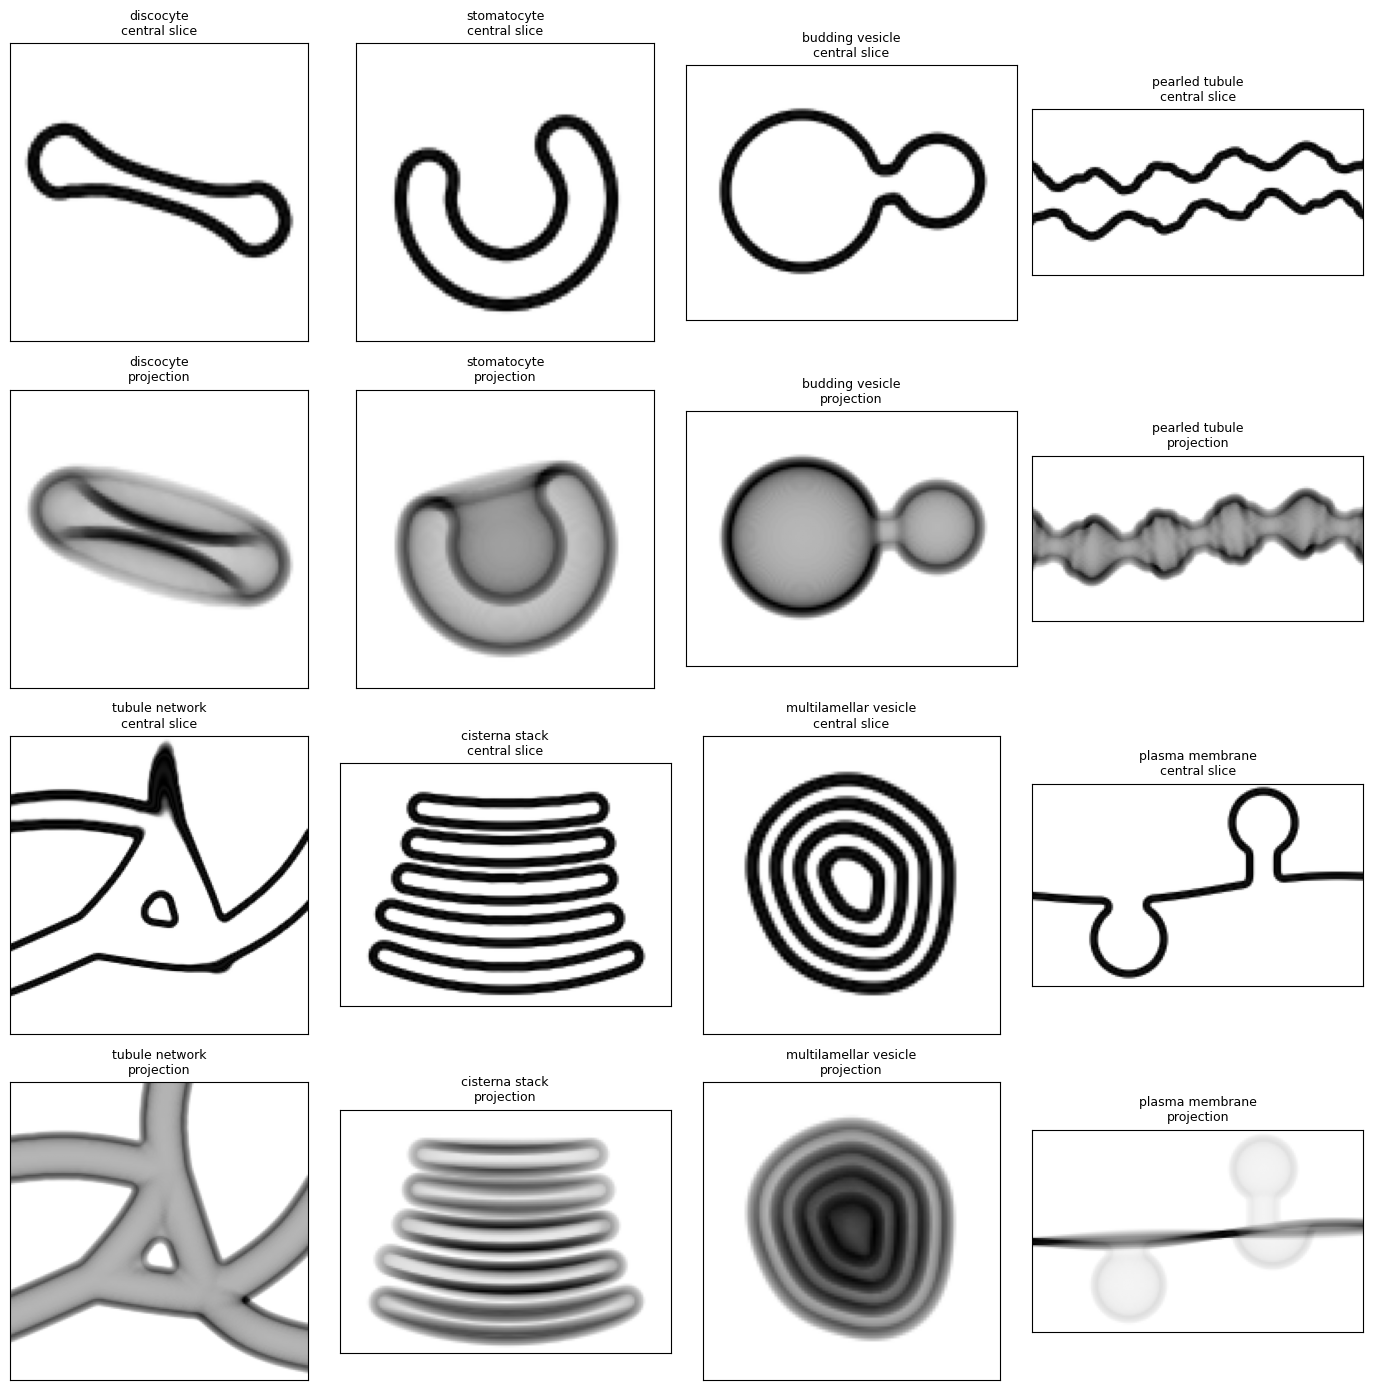

In [15]:
recipes = [
    (discocyte, 1),
    (stomatocyte, 1),
    (budding_vesicle, 0),
    (pearled_tubule, 0),
    (tubule_network, 0),
    (cisterna_stack, 1),
    (multilamellar_vesicle, 0),
    (plasma_membrane, 1),
]
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for index, (recipe, axis) in enumerate(recipes):
    (g, surfaces), seconds = timed(recipe, np.random.default_rng(0))
    volume = render(surfaces, g)
    weakest = min(
        min(float(o.min()), float(i.min()))
        for _, _, o, i in (reach(s, g) for s in surfaces)
    )
    print(
        f"{recipe.__name__:<22} {len(surfaces)} surface(s), geometry {seconds:4.1f} s, "
        f"min reach {weakest:4.1f} Å"
    )
    row, column = 2 * (index // 4), index % 4
    show(
        volume,
        10.0,
        recipe.__name__.replace("_", " "),
        axes[row : row + 2, column],
        axis=axis,
    )
fig.tight_layout()

### When a shape cannot be regularised

`regularise` repairs what it can: a neck of solvent thinner than the bilayer is filled, a
web of lumen too thin to hold two leaflets is removed, and the ball is rolled again, up to
`rounds` times (5 by default). If the measured reach is still below `min_reach` after
that, it raises `ReachError` (a `ValueError`) instead of returning a surface whose
leaflets would cross.

In practice the repair is hard to defeat: parallel sheets a few nm apart merge, a thin
shell disappears, and a folded tube fuses with itself. The shapes that fail are rough at a
scale close to the ball's radius, where each repair creates new thin features. The cell
below roughens a ball with relief of 150 Å standard deviation and 120 Å wavelength, far
beyond anything a membrane does. Some seeds regularise and some do not; which ones can
differ between devices, since the outcome depends on floating-point details near the
threshold.

`MembraneGenerator.generate` handles this case itself for the kinds with path-dependent
randomness: it redraws the shape a few times and raises `ReachError` only if every draw
fails. A recipe written by hand should either catch the error and redraw, as below, or be
made gentler (larger radii, wider gaps, less relief).

In [16]:
g = Grid((800.0, 800.0, 800.0), device=device)
for seed in (0, 1, 5):
    rough = prim.undulate(
        prim.ball(g, g.centre, 300.0), g, np.random.default_rng(seed), 150.0, 120.0
    )
    try:
        regularise(rough, g)
        print(f"seed {seed}: regularised")
    except ReachError as error:
        print(f"seed {seed}: ReachError: {error}")

seed 0: ReachError: membrane reach 20.0 A is below 25.0 A after 5 repairs


seed 1: regularised


seed 5: ReachError: membrane reach 22.5 A is below 25.0 A after 5 repairs


Two limits of the check are worth knowing when composing by hand. The reach is measured
per field, so two fields regularised separately (two sacs of a stack, two vesicles) are
not checked against each other, and keeping them more than a bilayer thickness apart is
the recipe's responsibility. And a solid that is too thin everywhere is removed entirely
rather than reported, leaving a field with no surface, so it is prudent to check that
`reach` returns some points.

## 3. Cost

The geometry lives on the coarse grid, so its cost depends on the organelle's size and
not on the output voxel size. Rendering visits only the output voxels within a few nm of
a surface, so its cost follows the membrane's area divided by the voxel size squared (and
the bilayer's fixed thickness in voxels), not the box volume.

The first cell times a whole `generate()` call for the same vesicle at two voxel sizes.
The second separates the two stages for the multilamellar recipe, whose four surfaces
give the renderer the most area.

In [17]:
for size in (12.0, 6.0):
    gen = MembraneGenerator(
        kind="vesicle", radius=300.0, voxel_size=size, device=device, seed=3
    )
    volume, seconds = timed(gen.generate)
    print(
        f"voxel size {size:4.1f} Å: output {tuple(volume.shape)} "
        f"({volume.numel() / 1e6:5.1f} M voxels), generate {seconds:.2f} s"
    )

voxel size 12.0 Å: output (84, 84, 84) (  0.6 M voxels), generate 0.48 s


voxel size  6.0 Å: output (164, 164, 164) (  4.4 M voxels), generate 0.50 s


In [18]:
(g, surfaces), geometry_seconds = timed(multilamellar_vesicle, np.random.default_rng(0))
print(
    f"geometry (4 surfaces, {g.n_nodes / 1e6:.1f} M coarse nodes): {geometry_seconds:.2f} s"
)
for size in (16.0, 8.0, 4.0):
    volume, seconds = timed(render, surfaces, g, size)
    occupied = float((volume != 0).float().mean())
    print(
        f"render at {size:4.1f} Å: {volume.numel() / 1e6:6.1f} M voxels, "
        f"{100 * occupied:4.1f}% within the bilayer, {seconds:.2f} s"
    )
    del volume

geometry (4 surfaces, 1.8 M coarse nodes): 1.58 s
render at 16.0 Å:    0.2 M voxels, 26.0% within the bilayer, 0.03 s
render at  8.0 Å:    2.0 M voxels, 24.5% within the bilayer, 0.02 s
render at  4.0 Å:   15.6 M voxels, 24.1% within the bilayer, 0.07 s


The geometry time is the same in every row. Halving the voxel size multiplies the box
volume by eight, while the render time grows more slowly, because only the voxels near a
membrane are evaluated.

## Where to go next

- `specter build tomogram` places these organelles in a crowded volume, embeds
  transmembrane proteins in them and labels the lumen and cytosol; see
  `../create_tilt_series_modular/` for a notebook that builds such a specimen and images
  it as a tilt series.
- `configs/tomogram.toml` documents every `[[membrane]]` setting.